# 01 — Data Understanding & Exploratory Data Analysis (EDA)

**Proyek:** Pengembangan *Domain-Informed Feature-Weighted K-Nearest Neighbors* (`DIFW-KNN`) untuk Klasifikasi Bank Marketing  
**Dataset:** `bank-full.csv` (UCI Machine Learning Repository — Dataset ID 222)  
**Versi Skrip Reproducible:** [`src/01_eda.py`](../src/01_eda.py)

Notebook ini mendokumentasikan analisis data eksploratif secara bertahap untuk menjawab pertanyaan kunci sebelum tahap *preprocessing*:
1. Bagaimana dimensi, kelengkapan (`NaN`), duplikasi, dan tingkat ketidakseimbangan kelas target `y`?
2. Mengapa kategori `"unknown"` pada fitur kategorikal harus dipertahankan?
3. Mengapa normalisasi interkuantil terklip $Q_{95} - Q_{05}$ dibutuhkan pada *Mixed-Type Distance*?
4. Bagaimana karakteristik sentinel `pdays = -1` dan bukti empiris *target leakage* pada `duration`?
5. Fitur mana yang memiliki daya diskriminatif tertinggi sebagai dasar *Supervised Triplet Feature Weighting*?

## 1. Akuisisi Data & Pemeriksaan Kualitas Awal

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import OrdinalEncoder
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.edgecolor': '#CCCCCC',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
    'axes.titleweight': 'bold',
})

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = PROJECT_ROOT / 'data' / 'bank-full.csv'

df = pd.read_csv(DATA_PATH, sep=';')
NUMERIC_COLS = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
CATEGORICAL_COLS = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
TARGET_COL = 'y'

print(f'Dimensi dataset : {df.shape[0]:,} baris x {df.shape[1]} kolom')
print(f'Total NaN       : {int(df.isna().sum().sum())}')
print(f'Baris duplikat  : {int(df.duplicated().sum())}')
print(f'Fitur numerik ({len(NUMERIC_COLS)})    : {NUMERIC_COLS}')
print(f'Fitur kategorikal ({len(CATEGORICAL_COLS)}): {CATEGORICAL_COLS}')

schema_df = pd.DataFrame({
    'feature': df.columns,
    'dtype': [str(t) for t in df.dtypes],
    'n_unique': [int(df[c].nunique()) for c in df.columns],
    'n_nan': [int(df[c].isna().sum()) for c in df.columns],
})
display(schema_df)
display(df.head(5))

Dimensi dataset : 45,211 baris x 17 kolom
Total NaN       : 0
Baris duplikat  : 0
Fitur numerik (7)    : ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Fitur kategorikal (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


,feature,dtype,n_unique,n_nan
0,age,int64,77,0
1,job,object,12,0
2,marital,object,3,0
3,education,object,4,0
4,default,object,2,0
5,balance,int64,7168,0
6,housing,object,2,0
7,loan,object,2,0
8,contact,object,3,0
9,day,int64,31,0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2. Distribusi Kelas Target (`y`) & Audit Kategori `"unknown"`

Dataset Bank Marketing memiliki ketimpangan kelas (*imbalanced binary classification*). Selain itu, ketiadaan nilai `NaN` bukan berarti data bebas *missing* secara semantik, karena beberapa fitur kategorikal menggunakan string `"unknown"`.

Kelas 'no'  : 39,922 (88.30%)
Kelas 'yes' : 5,289 (11.70%)
Imbalance Ratio (no : yes) = 7.55 : 1


,feature,n_unique,n_unknown,pct_unknown,yes_rate_when_unknown_pct
3,poutcome,4,36959,81.75,9.16
2,contact,3,13020,28.80,4.07
1,education,4,1857,4.11,13.57
0,job,12,288,0.64,11.81


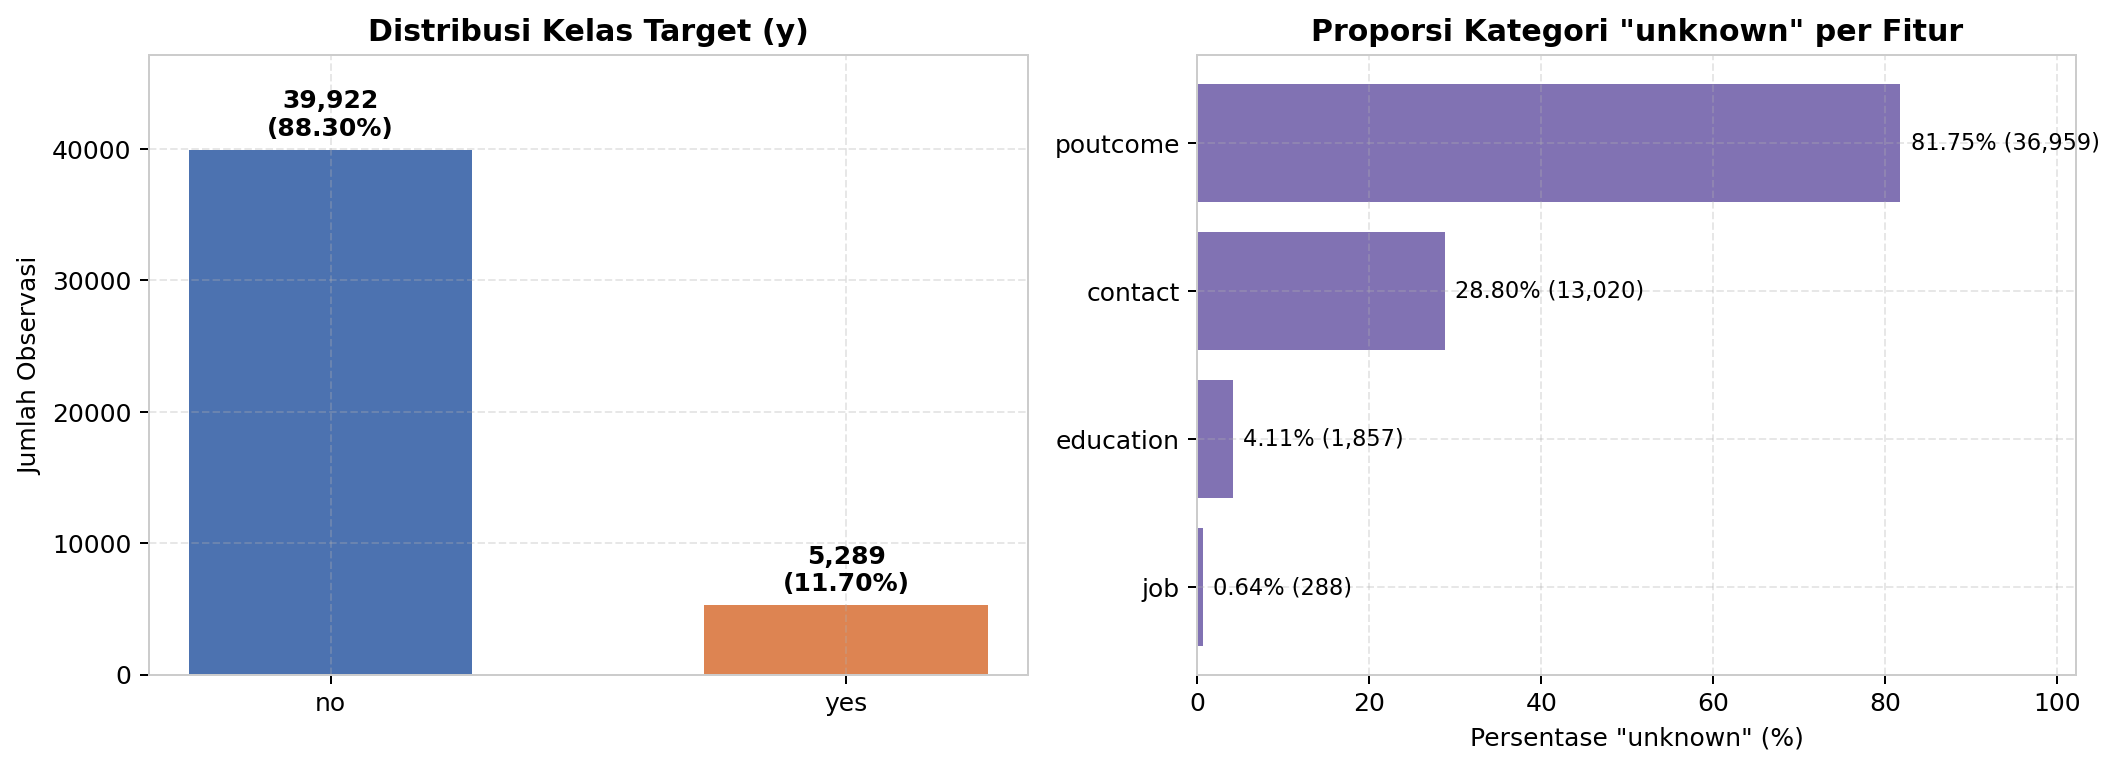

In [2]:
target_counts = df[TARGET_COL].value_counts().reindex(['no', 'yes'])
n_no, n_yes = int(target_counts['no']), int(target_counts['yes'])
imbalance_ratio = n_no / n_yes
baseline_pct = 100.0 * n_yes / len(df)

print(f"Kelas 'no'  : {n_no:,} ({100.0 * n_no / len(df):.2f}%)")
print(f"Kelas 'yes' : {n_yes:,} ({baseline_pct:.2f}%)")
print(f"Imbalance Ratio (no : yes) = {imbalance_ratio:.2f} : 1")

unk_rows = []
for col in CATEGORICAL_COLS:
    n_unk = int((df[col].astype(str).str.lower() == 'unknown').sum())
    if n_unk > 0:
        yes_rate_unk = 100.0 * (df.loc[df[col] == 'unknown', TARGET_COL] == 'yes').mean()
        unk_rows.append({
            'feature': col,
            'n_unique': int(df[col].nunique()),
            'n_unknown': n_unk,
            'pct_unknown': round(100.0 * n_unk / len(df), 2),
            'yes_rate_when_unknown_pct': round(yes_rate_unk, 2),
        })
unk_df = pd.DataFrame(unk_rows).sort_values('pct_unknown', ascending=False)
display(unk_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
bars = axes[0].bar(target_counts.index, target_counts.values, color=['#4C72B0', '#DD8452'], width=0.55)
axes[0].set_title('Distribusi Kelas Target (y)')
axes[0].set_ylabel('Jumlah Observasi')
axes[0].set_ylim(0, target_counts.max() * 1.18)
for bar, count in zip(bars, target_counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 700,
                 f'{count:,}\n({100*count/len(df):.2f}%)', ha='center', va='bottom', fontweight='bold')

unk_plot = unk_df.sort_values('pct_unknown', ascending=True)
bars_u = axes[1].barh(unk_plot['feature'], unk_plot['pct_unknown'], color='#8172B3')
axes[1].set_title('Proporsi Kategori "unknown" per Fitur')
axes[1].set_xlabel('Persentase "unknown" (%)')
axes[1].set_xlim(0, unk_plot['pct_unknown'].max() * 1.25)
for bar, (_, r) in zip(bars_u, unk_plot.iterrows()):
    axes[1].text(bar.get_width() + 1.2, bar.get_y() + bar.get_height() / 2,
                 f"{r['pct_unknown']:.2f}% ({int(r['n_unknown']):,})", va='center', fontsize=9)
fig.tight_layout()
plt.show()

## 3. Profil Statistik Fitur Numerik & Implikasi *Mixed-Type Distance*

Pada algoritma usulan **DIFW-KNN**, jarak fitur numerik dirumuskan menggunakan rentang interkuantil terklip $Q_{95} - Q_{05}$:
$$d_j(x, z) = \min\left(1,\; \frac{|x_j - z_j|}{Q_{95,j} - Q_{05,j}}\right)$$
Di bawah ini diperiksa *skewness*, outlier IQR, rentang $Q_{95} - Q_{05}$, serta uji beda antar kelas `y=yes` vs `y=no` (*Mann-Whitney U*, *Point-Biserial r*, dan *Single-Feature AUC*).

,feature,mean,std,min,q05,q25,median,q75,q95,max,q95_minus_q05,skewness,pct_outliers_iqr
0,age,40.9362,10.6188,18.0,27.0,33.0,39.0,48.0,59.0,95.0,32.0,0.6848,1.08
1,balance,1362.2721,3044.7658,-8019.0,-172.0,72.0,448.0,1428.0,5768.0,102127.0,5940.0,8.3603,10.46
2,day,15.8064,8.3225,1.0,3.0,8.0,16.0,21.0,29.0,31.0,26.0,0.0931,0.00
3,duration,258.1631,257.5278,0.0,35.0,103.0,180.0,319.0,751.0,4918.0,716.0,3.1443,7.16
4,campaign,2.7638,3.0980,1.0,1.0,1.0,2.0,3.0,8.0,63.0,7.0,4.8987,6.78
5,pdays,40.1978,100.1287,-1.0,-1.0,-1.0,-1.0,-1.0,317.0,871.0,318.0,2.6157,18.26
6,previous,0.5803,2.3034,0.0,0.0,0.0,0.0,0.0,3.0,275.0,3.0,41.8465,18.26


,feature,mean_no,median_no,mean_yes,median_yes,point_biserial_r,single_feature_auc,mw_pvalue
0,age,40.8390,39.0,41.6701,38.0,0.0252,0.5079,6.281791e-02
1,balance,1303.7150,417.0,1804.2679,733.0,0.0528,0.5901,6.593846e-101
2,day,15.8923,16.0,15.1583,15.0,-0.0283,0.5265,3.326079e-10
3,duration,221.1828,164.0,537.2946,426.0,0.3945,0.8076,0.000000e+00
4,campaign,2.8464,2.0,2.1410,2.0,-0.0732,0.5723,1.948490e-71
5,pdays,36.4214,-1.0,68.7030,-1.0,0.1036,0.5932,2.484118e-235
6,previous,0.5022,0.0,1.1704,0.0,0.0932,0.6023,3.491824e-283


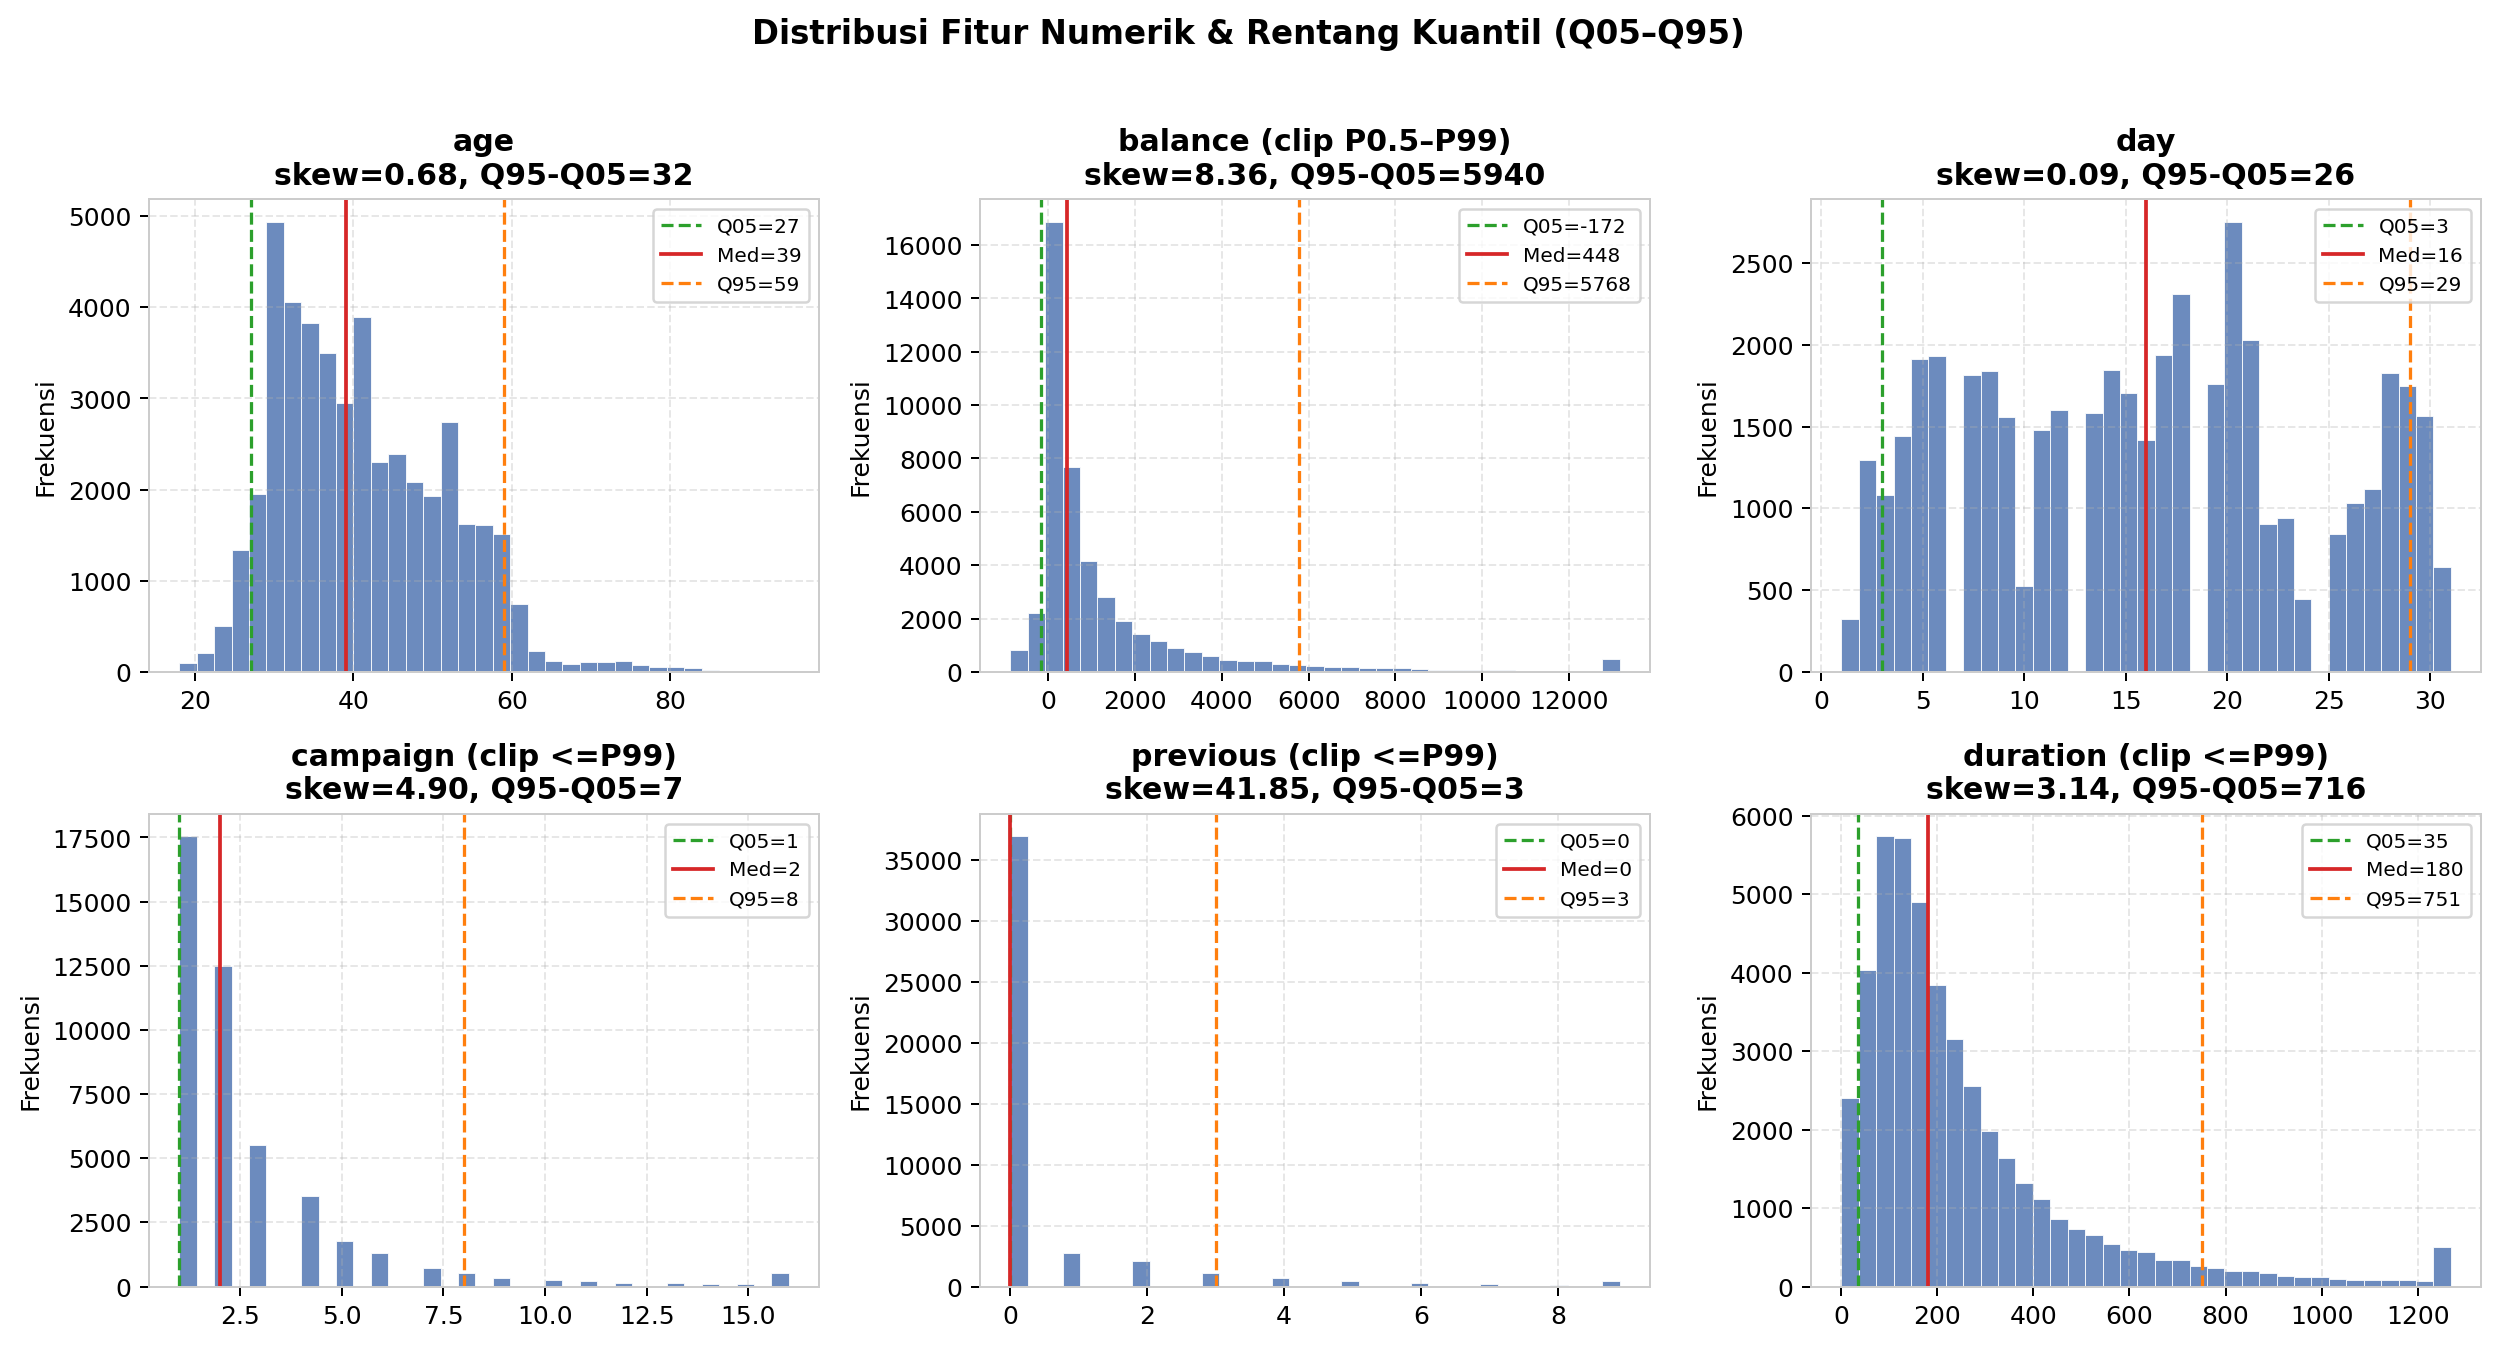

In [3]:
num_rows = []
y_bin = (df[TARGET_COL] == 'yes').astype(int)
target_comp_rows = []

for col in NUMERIC_COLS:
    s = df[col].astype(float)
    q05, q25, q50, q75, q95 = s.quantile([0.05, 0.25, 0.50, 0.75, 0.95])
    iqr = q75 - q25
    n_out = int(((s < q25 - 1.5 * iqr) | (s > q75 + 1.5 * iqr)).sum())
    num_rows.append({
        'feature': col,
        'mean': round(float(s.mean()), 4),
        'std': round(float(s.std(ddof=1)), 4),
        'min': float(s.min()),
        'q05': round(float(q05), 4),
        'q25': round(float(q25), 4),
        'median': round(float(q50), 4),
        'q75': round(float(q75), 4),
        'q95': round(float(q95), 4),
        'max': float(s.max()),
        'q95_minus_q05': round(float(q95 - q05), 4),
        'skewness': round(float(s.skew()), 4),
        'pct_outliers_iqr': round(100.0 * n_out / len(df), 2),
    })

    s_yes = s[y_bin == 1]
    s_no = s[y_bin == 0]
    u_stat, u_pval = stats.mannwhitneyu(s_yes, s_no, alternative='two-sided')
    auc_eq = float(u_stat) / (len(s_yes) * len(s_no))
    r_pb, pb_pval = stats.pointbiserialr(y_bin, s)
    target_comp_rows.append({
        'feature': col,
        'mean_no': round(float(s_no.mean()), 4),
        'median_no': round(float(s_no.median()), 4),
        'mean_yes': round(float(s_yes.mean()), 4),
        'median_yes': round(float(s_yes.median()), 4),
        'point_biserial_r': round(float(r_pb), 4),
        'single_feature_auc': round(max(auc_eq, 1.0 - auc_eq), 4),
        'mw_pvalue': float(u_pval),
    })

display(pd.DataFrame(num_rows))
display(pd.DataFrame(target_comp_rows))

plot_num_cols = ['age', 'balance', 'day', 'campaign', 'previous', 'duration']
fig, axes = plt.subplots(2, 3, figsize=(14, 7.6))
for ax, col in zip(axes.flat, plot_num_cols):
    s = df[col].astype(float)
    q05, q50, q95 = s.quantile([0.05, 0.50, 0.95])
    lo = float(s.quantile(0.005)) if col == 'balance' else float(s.min())
    hi = float(s.quantile(0.99)) if col in {'balance', 'campaign', 'previous', 'duration'} else float(s.max())
    ax.hist(s.clip(lower=lo, upper=hi), bins=35, color='#4C72B0', alpha=0.82, edgecolor='white', linewidth=0.4)
    ax.axvline(q05, color='#2CA02C', linestyle='--', linewidth=1.3, label=f'Q05={q05:.0f}')
    ax.axvline(q50, color='#D62728', linestyle='-', linewidth=1.5, label=f'Med={q50:.0f}')
    ax.axvline(q95, color='#FF7F0E', linestyle='--', linewidth=1.3, label=f'Q95={q95:.0f}')
    suffix = ' (clip P0.5–P99)' if col == 'balance' else (' (clip <=P99)' if col in {'campaign', 'previous', 'duration'} else '')
    ax.set_title(f'{col}{suffix}\nskew={s.skew():.2f}, Q95-Q05={q95-q05:.0f}')
    ax.set_ylabel('Frekuensi')
    ax.legend(fontsize=8, loc='upper right')
fig.suptitle('Distribusi Fitur Numerik & Rentang Kuantil (Q05–Q95)', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 4. Bedah Fitur `pdays` (Sentinel `-1`) dan Bukti Empiris *Target Leakage* pada `duration`

- **`pdays = -1`** menandakan nasabah belum pernah dihubungi pada kampanye sebelumnya (`81,74%` data).
- **`duration`** hanya diketahui setelah panggilan telepon berakhir; dalam skenario *pre-call prediction*, fitur ini merupakan *target leakage*.

pdays = -1  : 36,954 (81.74%) | yes rate = 9.16%
pdays > -1  : 8,257 (18.26%) | yes rate = 23.07%
Subset pdays > -1 -> Q05=79.0, Median=194.0, Q95=370.0, Max=871
Konsistensi previous==0 saat pdays==-1 : 100.00%
Single-feature ROC-AUC (duration) = 0.8076


,pdays_bucket,count,yes_count,yes_rate_pct
0,Belum pernah (-1),36954,3384,9.16
1,1-90 hari,718,251,34.96
2,91-180 hari,2480,680,27.42
3,181-365 hari,4416,786,17.80
4,> 365 hari,643,188,29.24


,duration_bucket,count,yes_count,yes_rate_pct
0,0-60 dtk,4766,9,0.19
1,61-120 dtk,9278,202,2.18
2,121-180 dtk,8616,498,5.78
3,181-300 dtk,10277,1122,10.92
4,301-600 dtk,8484,1625,19.15
5,601-1200 dtk,3230,1487,46.04
6,> 1200 dtk,560,346,61.79


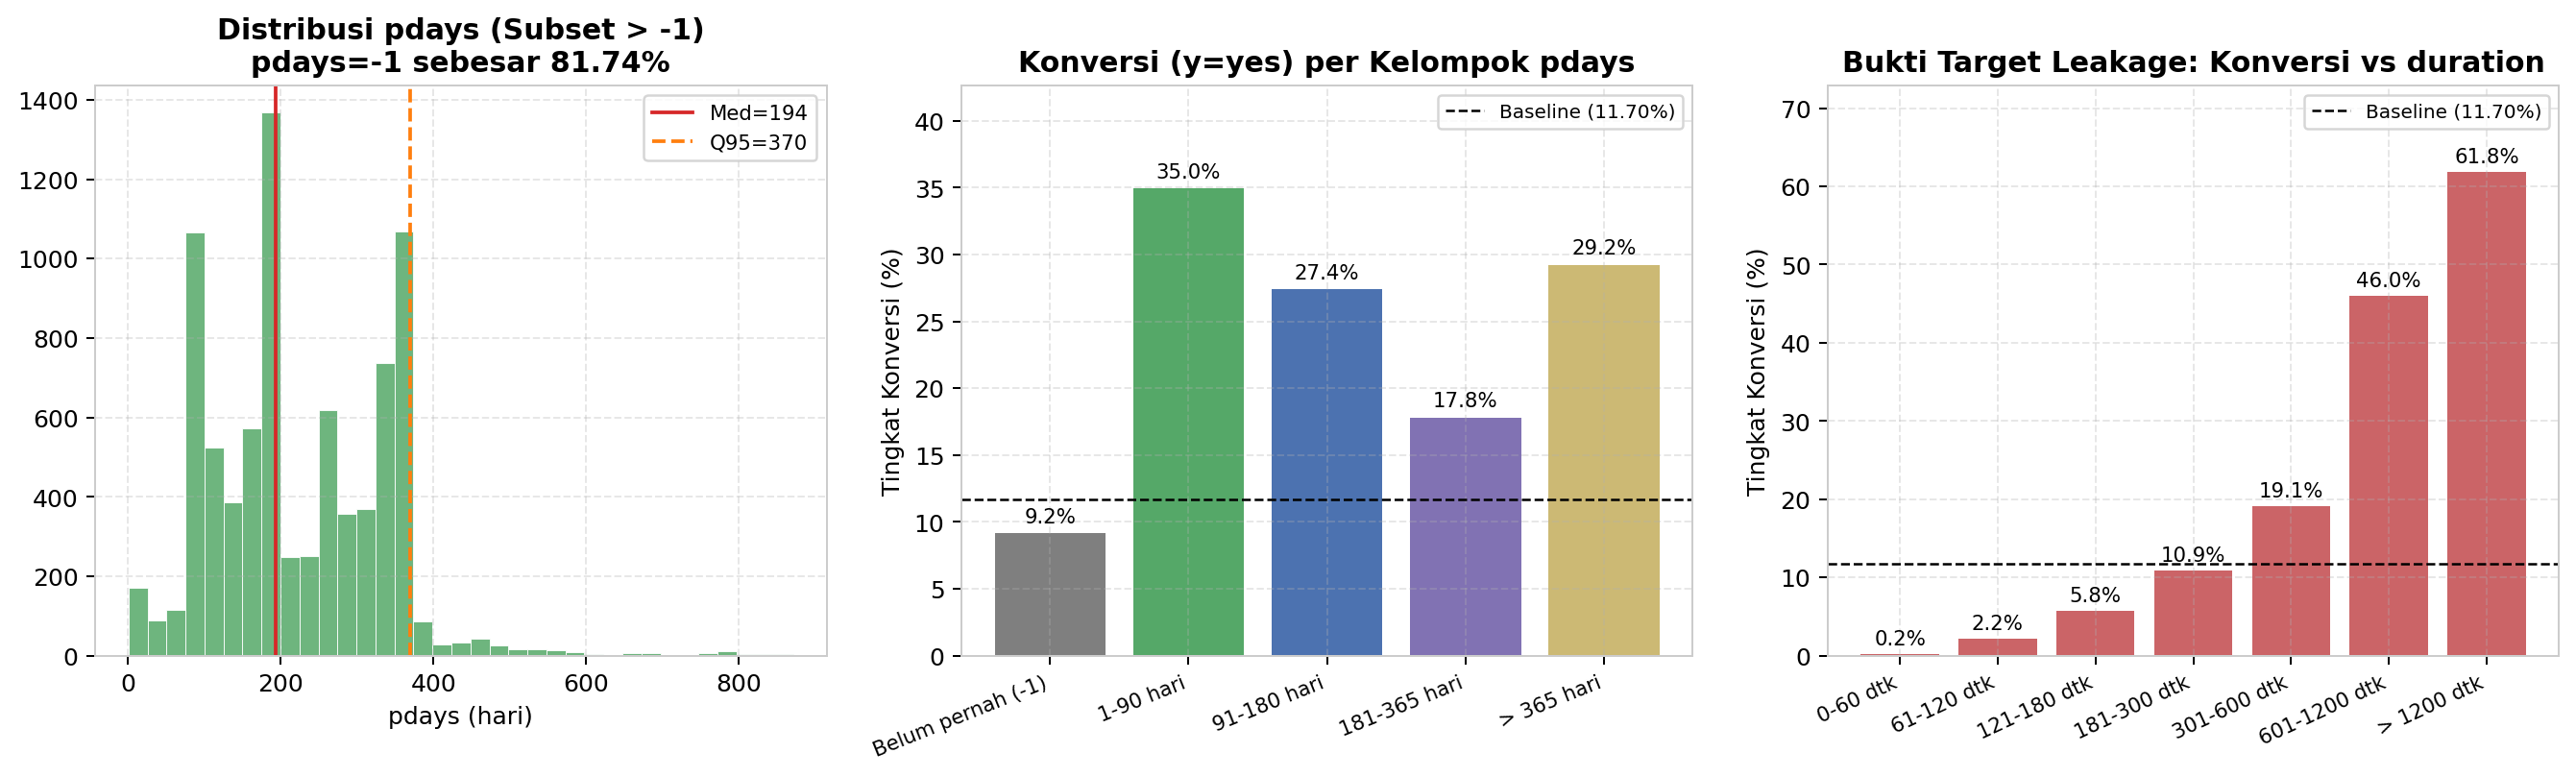

In [4]:
not_contacted = df['pdays'] == -1
contacted = df['pdays'] > -1
pdays_pos = df.loc[contacted, 'pdays'].astype(float)

print(f"pdays = -1  : {int(not_contacted.sum()):,} ({100*not_contacted.mean():.2f}%) | yes rate = {100*y_bin[not_contacted].mean():.2f}%")
print(f"pdays > -1  : {int(contacted.sum()):,} ({100*contacted.mean():.2f}%) | yes rate = {100*y_bin[contacted].mean():.2f}%")
print(f"Subset pdays > -1 -> Q05={pdays_pos.quantile(0.05):.1f}, Median={pdays_pos.median():.1f}, Q95={pdays_pos.quantile(0.95):.1f}, Max={pdays_pos.max():.0f}")
print(f"Konsistensi previous==0 saat pdays==-1 : {100*(df.loc[not_contacted, 'previous']==0).mean():.2f}%")

pdays_group = pd.Series('Belum pernah (-1)', index=df.index)
pdays_group.loc[(df['pdays'] >= 1) & (df['pdays'] <= 90)] = '1-90 hari'
pdays_group.loc[(df['pdays'] > 90) & (df['pdays'] <= 180)] = '91-180 hari'
pdays_group.loc[(df['pdays'] > 180) & (df['pdays'] <= 365)] = '181-365 hari'
pdays_group.loc[df['pdays'] > 365] = '> 365 hari'
order_p = ['Belum pernah (-1)', '1-90 hari', '91-180 hari', '181-365 hari', '> 365 hari']
pdays_tbl = df.assign(pdays_bucket=pdays_group, y_bin=y_bin).groupby('pdays_bucket', observed=False).agg(
    count=('y_bin', 'size'), yes_count=('y_bin', 'sum'), yes_rate_pct=('y_bin', lambda s: round(100*s.mean(), 2))
).reindex(order_p).reset_index()
display(pdays_tbl)

auc_dur = roc_auc_score(y_bin, df['duration'].astype(float))
print(f'Single-feature ROC-AUC (duration) = {auc_dur:.4f}')
dur_bins = [-0.1, 60, 120, 180, 300, 600, 1200, float('inf')]
dur_labels = ['0-60 dtk', '61-120 dtk', '121-180 dtk', '181-300 dtk', '301-600 dtk', '601-1200 dtk', '> 1200 dtk']
dur_tbl = df.assign(duration_bucket=pd.cut(df['duration'], bins=dur_bins, labels=dur_labels), y_bin=y_bin).groupby(
    'duration_bucket', observed=False
).agg(count=('y_bin', 'size'), yes_count=('y_bin', 'sum'), yes_rate_pct=('y_bin', lambda s: round(100*s.mean(), 2))).reset_index()
display(dur_tbl)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
axes[0].hist(pdays_pos, bins=35, color='#55A868', alpha=0.85, edgecolor='white', linewidth=0.4)
axes[0].axvline(pdays_pos.median(), color='#D62728', linestyle='-', label=f'Med={pdays_pos.median():.0f}')
axes[0].axvline(pdays_pos.quantile(0.95), color='#FF7F0E', linestyle='--', label=f'Q95={pdays_pos.quantile(0.95):.0f}')
axes[0].set_title(f'Distribusi pdays (Subset > -1)\npdays=-1 sebesar {100*not_contacted.mean():.2f}%')
axes[0].set_xlabel('pdays (hari)')
axes[0].legend(fontsize=8.5)

bp = axes[1].bar(range(len(pdays_tbl)), pdays_tbl['yes_rate_pct'], color=['#7F7F7F', '#55A868', '#4C72B0', '#8172B3', '#CCB974'])
axes[1].axhline(baseline_pct, color='black', linestyle='--', linewidth=1, label=f'Baseline ({baseline_pct:.2f}%)')
axes[1].set_xticks(range(len(pdays_tbl)))
axes[1].set_xticklabels(pdays_tbl['pdays_bucket'], rotation=22, ha='right', fontsize=8.5)
axes[1].set_title('Konversi (y=yes) per Kelompok pdays')
axes[1].set_ylabel('Tingkat Konversi (%)')
axes[1].set_ylim(0, pdays_tbl['yes_rate_pct'].max() * 1.22)
axes[1].legend(fontsize=8)
for bar, val in zip(bp, pdays_tbl['yes_rate_pct']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8, f'{val:.1f}%', ha='center', fontsize=8.5)

bd = axes[2].bar(range(len(dur_tbl)), dur_tbl['yes_rate_pct'], color='#C44E52', alpha=0.88)
axes[2].axhline(baseline_pct, color='black', linestyle='--', linewidth=1, label=f'Baseline ({baseline_pct:.2f}%)')
axes[2].set_xticks(range(len(dur_tbl)))
axes[2].set_xticklabels(dur_tbl['duration_bucket'], rotation=25, ha='right', fontsize=8.5)
axes[2].set_title('Bukti Target Leakage: Konversi vs duration')
axes[2].set_ylabel('Tingkat Konversi (%)')
axes[2].set_ylim(0, dur_tbl['yes_rate_pct'].max() * 1.18)
axes[2].legend(fontsize=8)
for bar, val in zip(bd, dur_tbl['yes_rate_pct']):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.2, f'{val:.1f}%', ha='center', fontsize=8.5)
fig.tight_layout()
plt.show()

## 5. Kekuatan Diskriminatif Fitur (*Mutual Information*, *Chi-Square*, *Cramér's V*) & Konversi Kategorikal

,feature,is_leakage,mutual_information
3,duration,True,0.07090
15,poutcome,False,0.02940
5,pdays,False,0.02748
14,month,False,0.02435
1,balance,False,0.02234
13,contact,False,0.01363
0,age,False,0.01332
6,previous,False,0.01106
11,housing,False,0.00965
7,job,False,0.00826


,feature,n_categories,chi2,p_value,cramers_v
8,poutcome,4,4391.51,0.000000e+00,0.3117
7,month,12,3061.84,0.000000e+00,0.2602
6,contact,3,1035.71,1.251738e-225,0.1514
4,housing,2,874.82,2.918798e-192,0.1391
0,job,12,836.11,3.337122e-172,0.1360
2,education,4,238.92,1.626656e-51,0.0727
5,loan,2,209.62,1.665061e-47,0.0681
1,marital,3,196.50,2.145100e-43,0.0659
3,default,2,22.20,2.453861e-06,0.0222


,feature,category,count,pct_total,yes_count,yes_rate_pct,lift
42,poutcome,success,1511,3.34,978,64.73,5.533
41,poutcome,other,1840,4.07,307,16.68,1.426
40,poutcome,failure,4901,10.84,618,12.61,1.078
43,poutcome,unknown,36959,81.75,3386,9.16,0.783


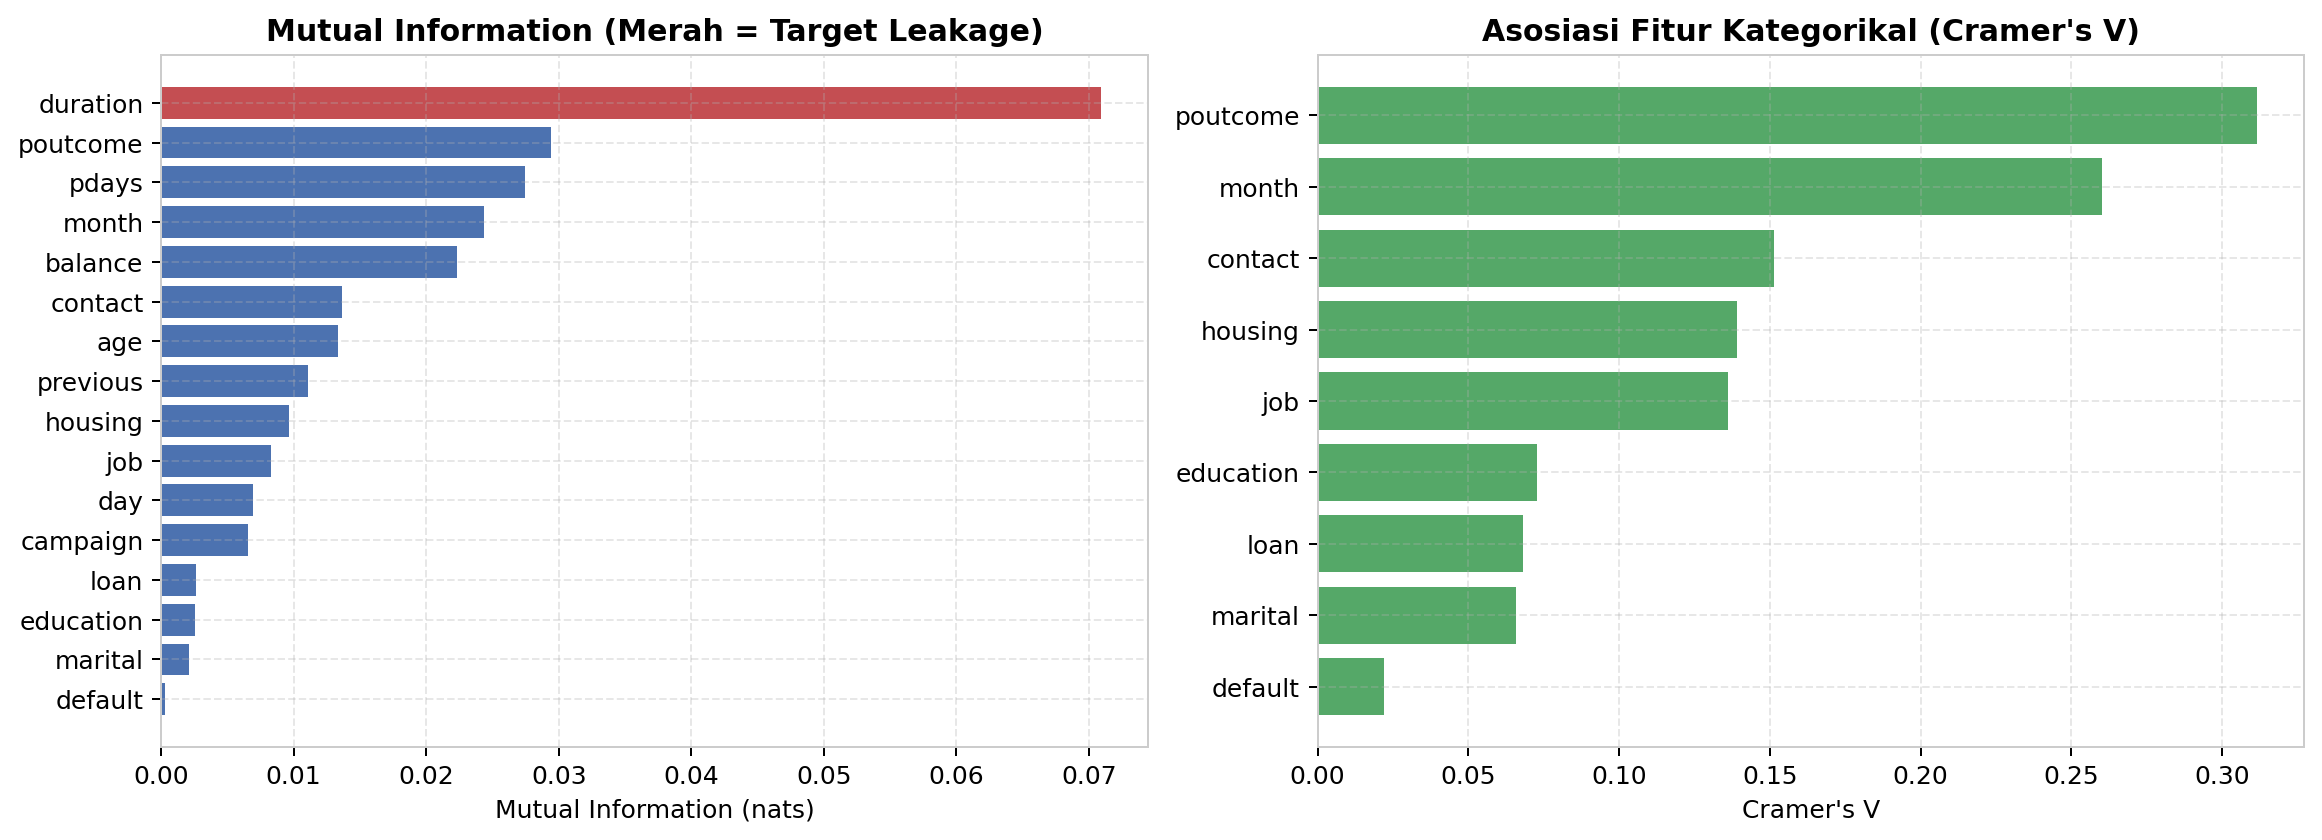

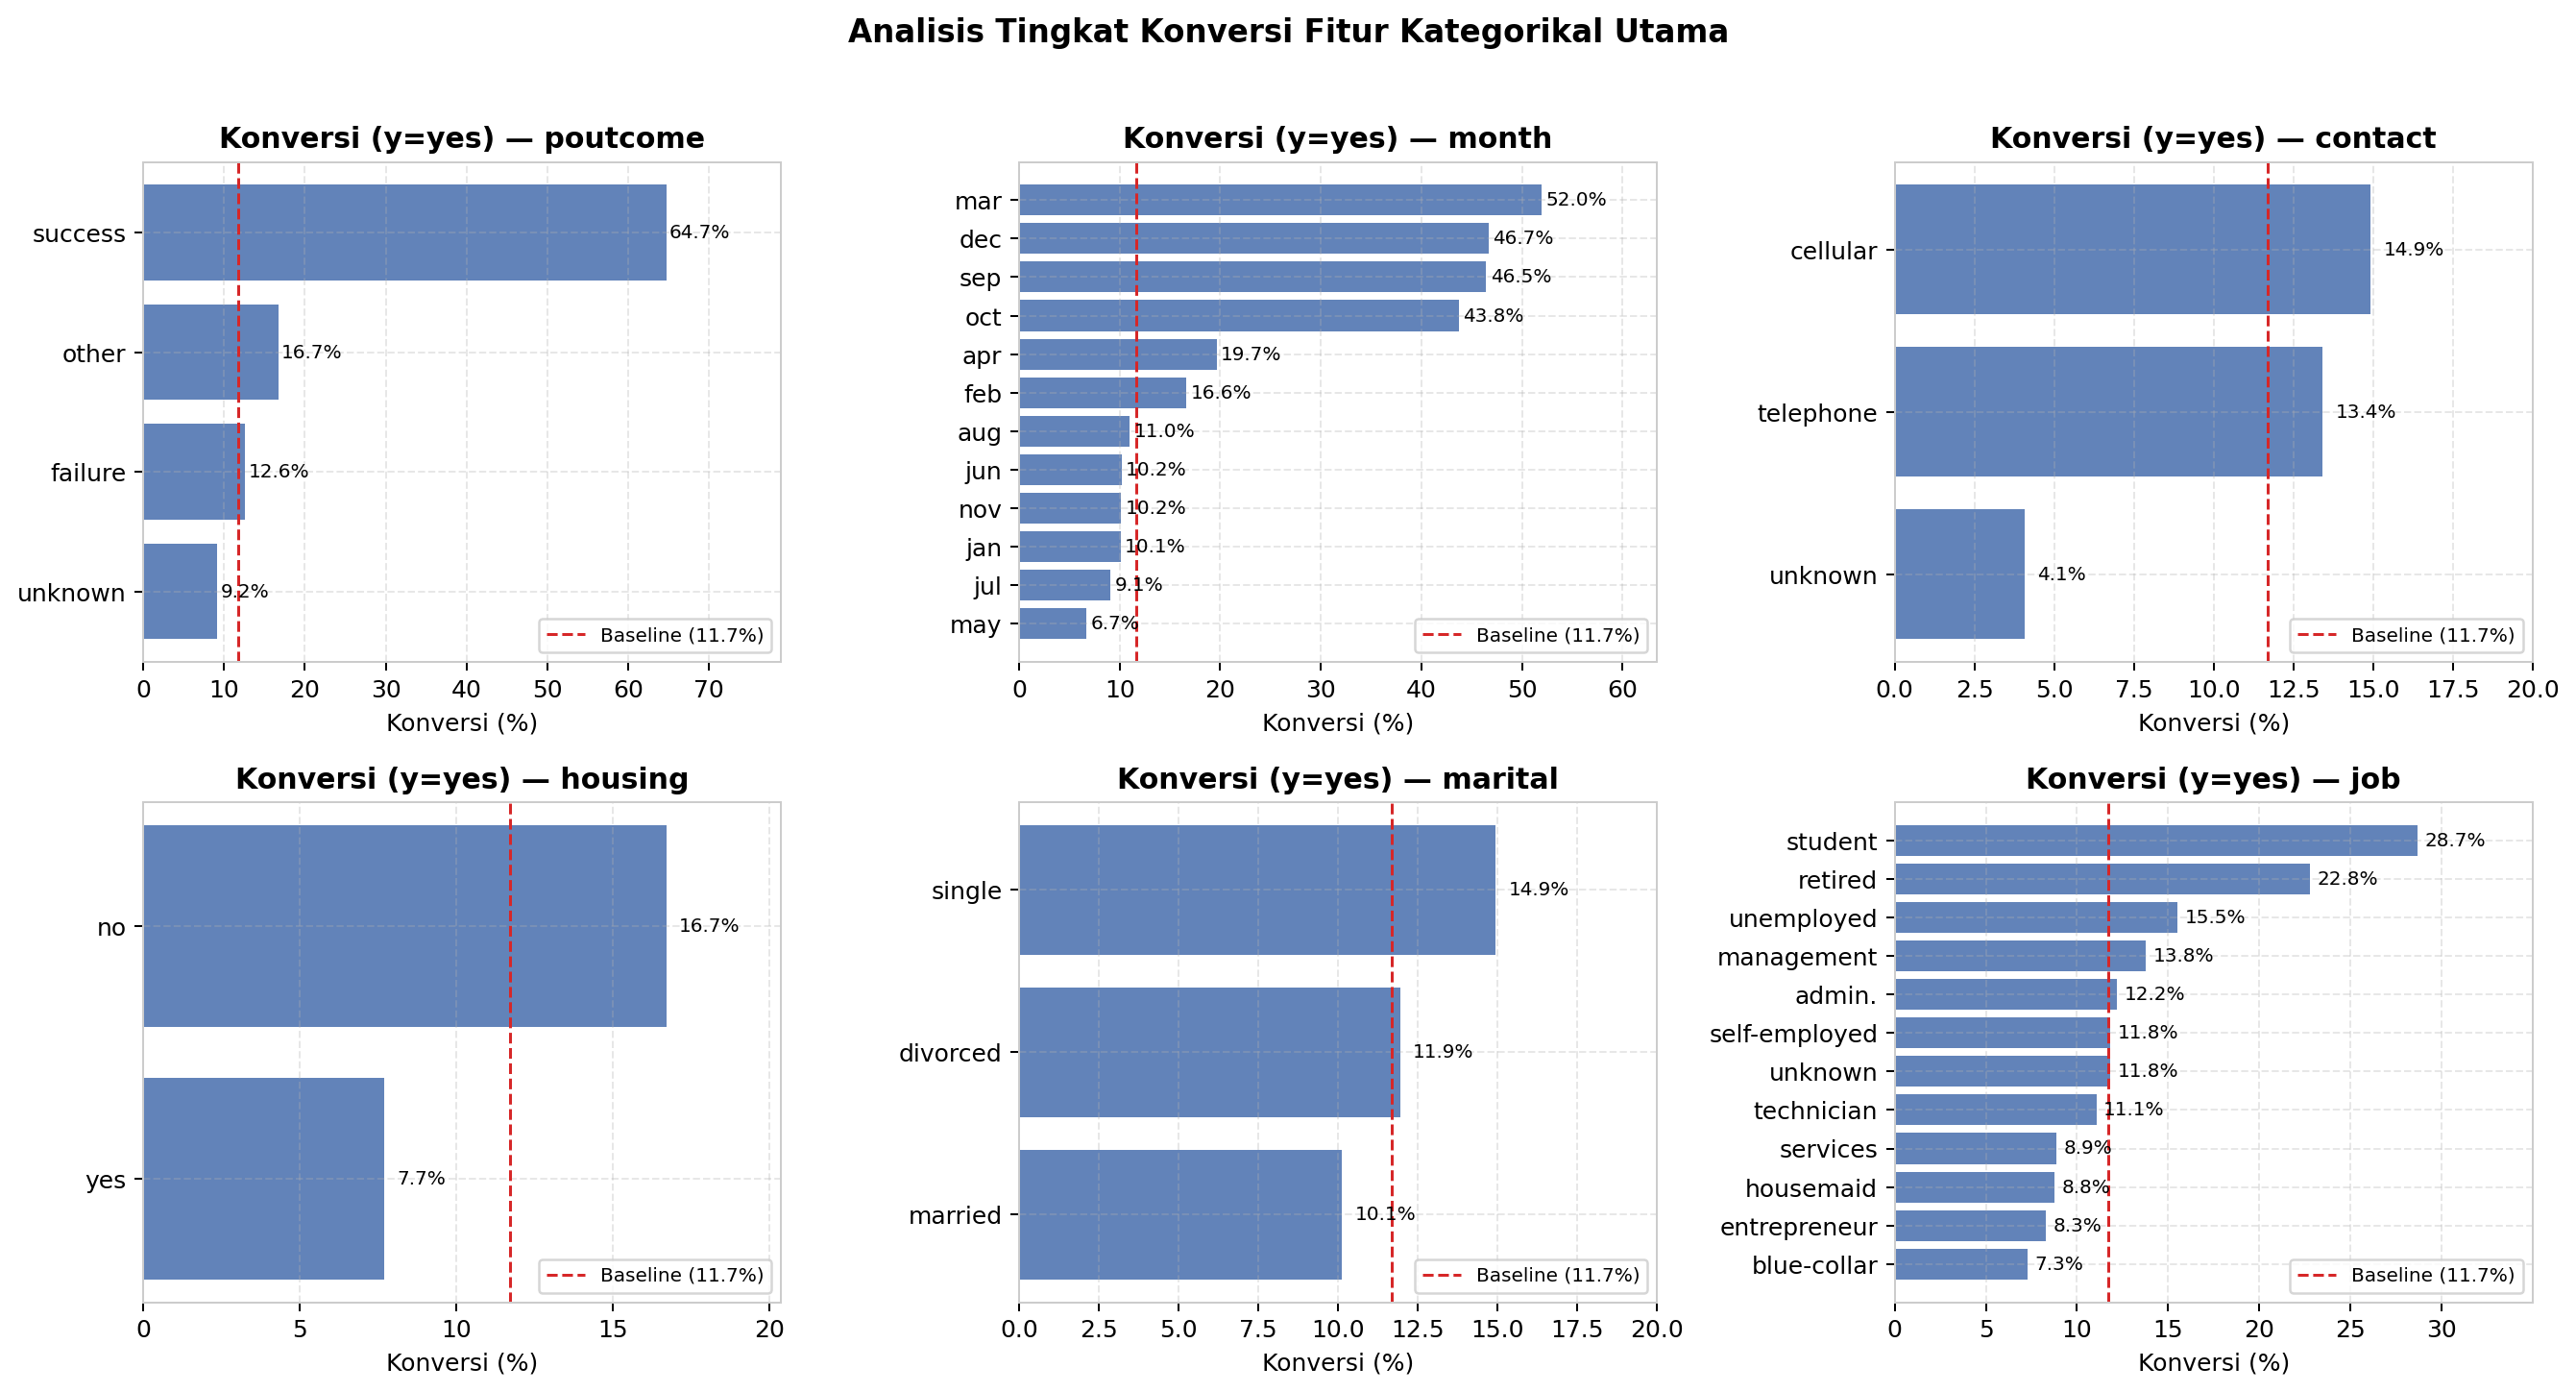

In [5]:
feat_cols = NUMERIC_COLS + CATEGORICAL_COLS
X_mi = pd.DataFrame(index=df.index)
discrete_mask = []
for col in NUMERIC_COLS:
    X_mi[col] = df[col].astype(float)
    discrete_mask.append(False)
enc_vals = OrdinalEncoder(dtype=np.int64).fit_transform(df[CATEGORICAL_COLS].astype(str))
for idx, col in enumerate(CATEGORICAL_COLS):
    X_mi[col] = enc_vals[:, idx]
    discrete_mask.append(True)

mi_scores = mutual_info_classif(X_mi, y_bin.to_numpy(), discrete_features=discrete_mask, random_state=42)
mi_df = pd.DataFrame({
    'feature': feat_cols,
    'is_leakage': [c == 'duration' for c in feat_cols],
    'mutual_information': np.round(mi_scores, 5),
}).sort_values('mutual_information', ascending=False)

cat_rows, detail_rows = [], []
baseline_rate = float(y_bin.mean())
for col in CATEGORICAL_COLS:
    ct = pd.crosstab(df[col], df[TARGET_COL])
    chi2, p_val, dof, _ = stats.chi2_contingency(ct)
    v = float(np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1))))
    cat_rows.append({'feature': col, 'n_categories': int(df[col].nunique()), 'chi2': round(float(chi2), 2), 'p_value': float(p_val), 'cramers_v': round(v, 4)})
    grp = df.assign(y_bin=y_bin).groupby(col, observed=False).agg(count=('y_bin', 'size'), yes_count=('y_bin', 'sum'), yes_rate=('y_bin', 'mean')).reset_index()
    for _, r in grp.iterrows():
        detail_rows.append({'feature': col, 'category': str(r[col]), 'count': int(r['count']), 'pct_total': round(100*r['count']/len(df), 2), 'yes_count': int(r['yes_count']), 'yes_rate_pct': round(100*r['yes_rate'], 2), 'lift': round(float(r['yes_rate'])/baseline_rate, 3)})

cat_summary = pd.DataFrame(cat_rows).sort_values('cramers_v', ascending=False)
cat_detail = pd.DataFrame(detail_rows)
display(mi_df)
display(cat_summary)
display(cat_detail[cat_detail['feature'] == 'poutcome'].sort_values('yes_rate_pct', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
mi_p = mi_df.sort_values('mutual_information', ascending=True)
axes[0].barh(mi_p['feature'], mi_p['mutual_information'], color=['#C44E52' if lk else '#4C72B0' for lk in mi_p['is_leakage']])
axes[0].set_title('Mutual Information (Merah = Target Leakage)')
axes[0].set_xlabel('Mutual Information (nats)')
cv_p = cat_summary.sort_values('cramers_v', ascending=True)
axes[1].barh(cv_p['feature'], cv_p['cramers_v'], color='#55A868')
axes[1].set_title("Asosiasi Fitur Kategorikal (Cramer's V)")
axes[1].set_xlabel("Cramer's V")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
for ax, col in zip(axes.flat, ['poutcome', 'month', 'contact', 'housing', 'marital', 'job']):
    sub = cat_detail[cat_detail['feature'] == col].sort_values('yes_rate_pct', ascending=True)
    bars_c = ax.barh(sub['category'], sub['yes_rate_pct'], color='#4C72B0', alpha=0.88)
    ax.axvline(baseline_pct, color='#D62728', linestyle='--', linewidth=1.2, label=f'Baseline ({baseline_pct:.1f}%)')
    ax.set_title(f'Konversi (y=yes) — {col}')
    ax.set_xlabel('Konversi (%)')
    ax.set_xlim(0, max(sub['yes_rate_pct'].max() * 1.22, 20))
    ax.legend(fontsize=8, loc='lower right')
    for bar, val in zip(bars_c, sub['yes_rate_pct']):
        ax.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height()/2, f'{val:.1f}%', va='center', fontsize=8)
fig.suptitle('Analisis Tingkat Konversi Fitur Kategorikal Utama', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()